#**Questão de negócio**

Uma empresa está interessada em verificar se a remuneração(salario) dos funcionarios está de acordo com as politicas da empresa.


Para isso uma amostra de 46 colaboradores foi disponibilisada

* Pergunta de negócio: O salario muda de acordo com os anos de educação superior
* Se muda, é possivel prever o salario apartir de um modelo ?

In [ ]:
#manipulação dos dados
import pandas as pd

#graficos
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

#statística
import statsmodels.api as sm

In [ ]:
df = pd.read_csv('base_funcionarios_v1.csv',sep=';',index_col='id')
display(df)

,Salario,Anos_Educ_Superior
id,,
1,5517.4,3
2,6399.9,4
3,6206.7,6
4,6060.6,4
5,6122.7,2
6,6955.0,5
7,7643.0,4
8,6210.2,2
9,5761.0,9


In [ ]:
df.isna().sum()

,0
Salario,0
Anos_Educ_Superior,0


In [ ]:
df.describe().round(2)

,Salario,Anos_Educ_Superior
count,46.00,46.00
mean,6969.80,5.07
std,1924.87,2.84
min,4139.50,0.00
25%,5818.35,4.00
50%,6394.75,5.00
75%,7972.40,6.00
max,12118.10,12.00


##Correlação linear de Person

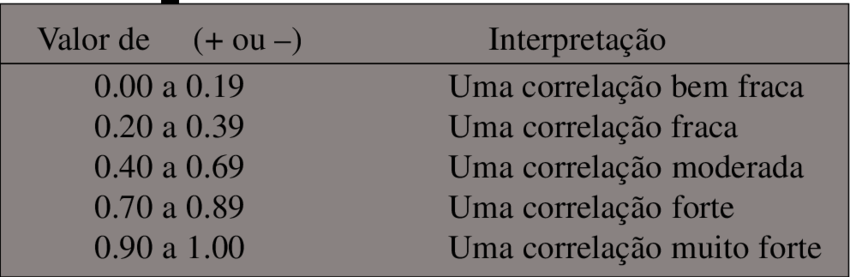

In [ ]:
df.corr()

,Salario,Anos_Educ_Superior
Salario,1.000000,0.776992
Anos_Educ_Superior,0.776992,1.000000


<Axes: xlabel='Anos_Educ_Superior', ylabel='Salario'>

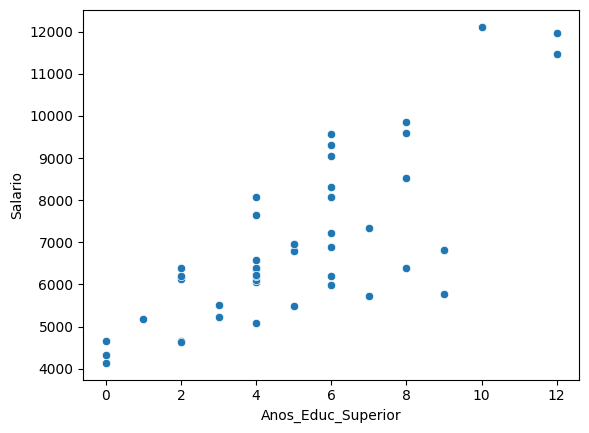

In [ ]:
sns.scatterplot(df, x='Anos_Educ_Superior', y='Salario')

<Axes: >

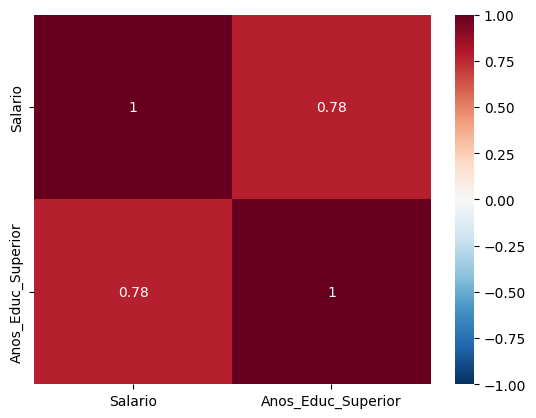

In [ ]:
sns.heatmap(
    df.corr(),
    vmin=-1,vmax=1,
    cmap= 'RdBu_r',
    annot=True
)

In [ ]:
#variavel alvo / target
y = df['Salario']

#variaveis independentes / explicativas
df['intercepto'] = 1
x = df[['Anos_Educ_Superior','intercepto']]

In [ ]:
#Ajuste do modelo
# minimos quadrados ordinarios
modelo = sm.OLS(y,x)

In [ ]:
#treinamento
resultado = modelo.fit()

In [ ]:
print(resultado.summary())

                            OLS Regression Results                            
Dep. Variable:                Salario   R-squared:                       0.604
Model:                            OLS   Adj. R-squared:                  0.595
Method:                 Least Squares   F-statistic:                     67.03
Date:                Tue, 17 Nov 2026   Prob (F-statistic):           2.18e-10
Time:                        19:35:34   Log-Likelihood:                -391.36
No. Observations:                  46   AIC:                             786.7
Df Residuals:                      44   BIC:                             790.4
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Anos_Educ_Superior   526.7294     64

In [ ]:
df['Novo Salario'] = df['Anos_Educ_Superior'] * 526.73 + 4301.80
display(df)

,Salario,Anos_Educ_Superior,intercepto,Novo Salario
id,,,,
1,5517.4,3,1,5881.99
2,6399.9,4,1,6408.72
3,6206.7,6,1,7462.18
4,6060.6,4,1,6408.72
5,6122.7,2,1,5355.26
6,6955.0,5,1,6935.45
7,7643.0,4,1,6408.72
8,6210.2,2,1,5355.26
9,5761.0,9,1,9042.37
